# EDA na Prática , Heart Failure Prediction

Atividade de EDA aplicada ao dataset *Heart Failure Prediction* (fedesoriano, Kaggle). São 918 pacientes e 11 variáveis clínicas, mais a indicação de presença ou ausência de doença cardíaca.

Segui a mesma sequência da aula: estrutura, dados faltantes, distribuição, tratamento, descritiva de novo e relações entre variáveis. Em alguns pontos o meu dataset pediu uma decisão diferente da que foi tomada em sala. Sempre que isso aconteceu eu deixei escrito o motivo.

A EDA não é uma linha reta. Em vários momentos aqui eu voltei atrás: descobri uma coisa na seção 3 que me fez mudar o que eu tinha feito na 2.

## Setup de bibliotecas e dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA   = "blue"
COR_CONTEXTO = "#e9d4d0"
COR_DESTAQUE = "#2d223a"
COR_ALERTA   = "tab:red"

PALETA = {"Normal": COR_CONTEXTO, "Cardíaco": COR_DESTAQUE}

## Carregando o dataset

In [ ]:
!pip install kagglehub --quiet
import kagglehub, os

path = kagglehub.dataset_download("fedesoriano/heart-failure-prediction")
df = pd.read_csv(os.path.join(path, "heart.csv"))
df.head()

Using Colab cache for faster access to the 'heart-failure-prediction' dataset.


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 1. Princípio estrutural


### Dimensão e tipos de dados

In [ ]:
df.shape

(918, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


São 918 linhas e 12 colunas. O `info()` mostra 918 valores não nulos em todas as colunas, ou seja, nenhum `NaN`. Porém, há algo que devemos observar no futuro.

Cinco colunas são texto (`Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, `ST_Slope`) e as outras sete são numéricas.

In [ ]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


Duas coisas chamam atenção nessa tabela:

O `min` de `RestingBP` é 0 e o `min` de `Cholesterol` também é 0. Pressão arterial em repouso zero e colesterol zero não existem em paciente vivo. Isso não é medição, é outra coisa.

A média do colesterol (198,8) é bem menor que a mediana (223,0). Quando a média fica abaixo da mediana desse jeito, normalmente tem um monte de valor baixo puxando ela.

### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

Nenhuma linha duplicada.

### Renomeando o atributo alvo

Na aula foi preciso transformar o alvo, porque lá ele ia de 0 a 4 (graus de doença) e foi simplificado para binário. No meu dataset o `HeartDisease` já nasce 0 ou 1, então não tem nada para simplificar. Só criei uma versão com o rótulo escrito, que é o que vai guiar as cores dos gráficos (rosa para sem doença, roxo para com doença).

Decidi manter também a coluna numérica original.

In [ ]:
df["doenca_cardiaca"] = np.where(df["HeartDisease"] > 0, "Cardíaco", "Normal")
print(df["doenca_cardiaca"].value_counts())
print(df["doenca_cardiaca"].value_counts(normalize=True).round(3))
df.head()

doenca_cardiaca
Cardíaco    508
Normal      410
Name: count, dtype: int64
doenca_cardiaca
Cardíaco    0.553
Normal      0.447
Name: proportion, dtype: float64


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,doenca_cardiaca
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0,Normal
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1,Cardíaco
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0,Normal
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1,Cardíaco
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0,Normal


São 508 pacientes com doença e 410 sem. As duas classes têm tamanhos parecidos, o que facilita a vida mais na frente.

## 2. Dados faltantes

In [ ]:
df.isna().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


**Discussão: alguma feature tem dados ausentes?**

Pelo `isna()`, nenhuma. Mas ausência de `NaN` não é a mesma coisa que ausência de dado faltante.

O `describe()` da seção 1 já tinha mostrado `min` igual a 0 em `RestingBP` e em `Cholesterol`. Como esses dois valores são impossíveis num paciente vivo, a conclusão é que a base guarda "não medido" como zero. É uma convenção comum em dados clínicos antigos, e ela engana o `isna()` porque zero é um número válido para o pandas.

Então a resposta é: sim, tem dados faltantes, só que disfarçados.

### Procurando zeros impossíveis

É necessário então olhar os zeros de todas as colunas numéricas. Zero só é suspeito quando é impossível naquele contexto, e isso depende de conhecimento clínico, não de estatística.

In [ ]:
num = df.select_dtypes(include=np.number)
print("Zeros por coluna numérica:")
print((num == 0).sum())

Zeros por coluna numérica:
Age               0
RestingBP         1
Cholesterol     172
FastingBS       704
MaxHR             0
Oldpeak         368
HeartDisease    410
dtype: int64


Três colunas têm muitos zeros, e eles são legítimos:

`FastingBS` tem 704 zeros, mas ela é binária e zero significa "glicemia de jejum normal".
`Oldpeak` tem 368 zeros, e zero ali quer dizer que não houve depressão do segmento ST no esforço.
`HeartDisease` tem 410 zeros, que são os pacientes sem doença.

Os zeros problemáticos são outros dois: 1 em `RestingBP` e 172 em `Cholesterol`. Esses eu converti para `NaN`.

In [ ]:
COLS_ZERO_INVALIDO = ["RestingBP", "Cholesterol"]
df[COLS_ZERO_INVALIDO] = df[COLS_ZERO_INVALIDO].replace(0, np.nan)

print("Ausentes depois da conversão:")
print(df.isna().sum()[lambda s: s > 0])
print("\nProporção de ausentes em Cholesterol: %.2f%%" % (100 * df["Cholesterol"].isna().mean()))

Ausentes depois da conversão:
RestingBP        1
Cholesterol    172
dtype: int64

Proporção de ausentes em Cholesterol: 18.74%


Agora aparecem 172 ausentes em `Cholesterol` (18,74% da base) e 1 em `RestingBP`.

### Identificando o mecanismo de dados ausentes

**Conhecimento de domínio**

As duas colunas com ausência são `Cholesterol` (colesterol sérico em mg/dl) e `RestingBP` (pressão arterial em repouso em mm Hg).

Como os dados foram coletados: este dataset é a junção de cinco bases do repositório UCI, que são Cleveland, Hungria, Suíça, Long Beach VA e Stalog. Depois de remover duplicatas sobraram 918 pacientes, vindos de países, hospitais e protocolos diferentes.

Qual é a natureza da fonte: são pacientes reais. Exame deixa de ser feito por custo, por protocolo do hospital ou porque a conduta clínica já estava decidida. Um volume de ausência tão alto e concentrado numa única coluna sugere que um dos centros de origem simplesmente não registrava colesterol.

**As ausências ocorrem juntas?**

Se duas colunas faltam nas mesmas linhas, isso indica um padrão sistemático, tipo um exame que não foi feito e derrubou várias medidas de uma vez.

Colunas com ausentes: ['RestingBP', 'Cholesterol']
RestingBP        1
Cholesterol    172
dtype: int64 



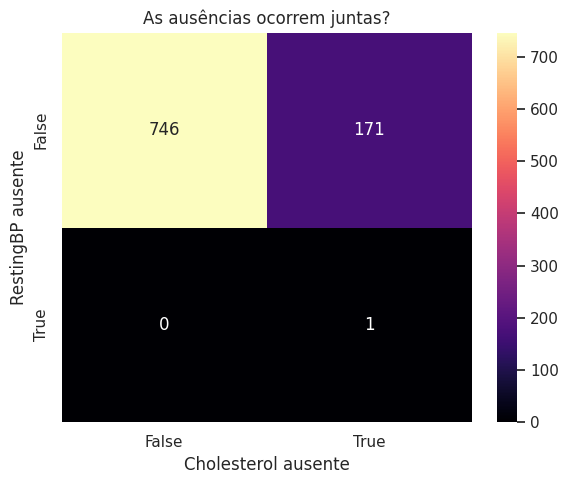

In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum(), "\n")

a, b = cols_com_ausentes[0], cols_com_ausentes[1]
tabela_contingencia = (pd.crosstab(df[a].isna(), df[b].isna())
                         .reindex(index=[False, True], columns=[False, True], fill_value=0))
tabela_contingencia.index.name = f"{a} ausente"
tabela_contingencia.columns.name = f"{b} ausente"

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo?

Nenhuma. O mapa mostra 746 pacientes com as duas medidas, 171 com só o colesterol faltando e 1 com só a pressão faltando. A casa das duas juntas está zerada.

Isso quer dizer que são eventos independentes, e que cada coluna tem o seu próprio mecanismo.

A pressão é uma linha entre 918, sem padrão nenhum. Parece falha isolada de registro, compatível com MCAR.

O colesterol é o caso interessante, e resolvi testar em vez de só supor.

In [ ]:
df["chol_ausente"] = df["Cholesterol"].isna()

abs_tab = pd.crosstab(df["chol_ausente"], df["doenca_cardiaca"])
prop = (pd.crosstab(df["chol_ausente"], df["doenca_cardiaca"], normalize="index") * 100).round(1)
display(abs_tab)
display(prop)

chi2, p, gl, esperado = stats.chi2_contingency(abs_tab)
print(f"Qui-quadrado = {chi2:.2f} | gl = {gl} | p-valor = {p:.3e}")

doenca_cardiaca,Cardíaco,Normal
chol_ausente,,
False,356,390
True,152,20


doenca_cardiaca,Cardíaco,Normal
chol_ausente,,
False,47.7,52.3
True,88.4,11.6


Qui-quadrado = 91.82 | gl = 1 | p-valor = 9.505e-22


Entre os pacientes que têm colesterol medido, 47,7% têm doença cardíaca. Entre os que não têm, 88,4% têm doença. São 152 dos 172 sem medição.

O qui-quadrado deu 91,82 com p-valor de 9,5 × 10⁻²², ou seja, praticamente zero. A chance de o exame estar faltando depende fortemente do desfecho do paciente.

Com isso, MCAR está descartado. Sobram duas hipóteses e os dados sozinhos não escolhem entre elas:

Se a causa for o hospital de origem, ou seja, um centro que não fazia o exame e que por acaso atendia casos mais graves, então a ausência depende de algo externo ao valor e isso é **MAR**. O viés é corrigível porque depende de uma variável observável.

Se a causa for a conduta clínica, ou seja, o médico não pediu o exame porque o quadro já estava definido, então a ausência depende do próprio valor que falta e isso é **MNAR**.


## 3. Princípio distribucional


In [ ]:
VARS_QUANT = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
VARS_QUALI = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["count", "mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,count,mean,median,std,min,max,skewness,kurtosis
Age,918.00,53.51,54.00,9.43,28.00,77.00,-0.20,-0.39
RestingBP,917.00,132.54,130.00,18.00,80.00,200.00,0.61,0.79
Cholesterol,746.00,244.64,237.00,59.15,85.00,603.00,1.24,4.53
MaxHR,918.00,136.81,138.00,25.46,60.00,202.00,-0.14,-0.45
Oldpeak,918.00,0.89,0.60,1.07,-2.60,6.20,1.02,1.20


 Aqui `Cholesterol` tem 746 e `RestingBP` tem 917, contra 918 das outras. Sem essa coluna, quem lê a tabela pensa que a média do colesterol foi calculada sobre a base inteira.

**Pra discutir: quais variáveis parecem assimétricas ou com cauda pesada?**

`Cholesterol` é a mais problemática: skewness 1,24 e curtose 4,53, de longe a maior da tabela. Faz sentido clinicamente, porque a maioria dos pacientes fica entre 200 e 300 e poucos chegam a 600, o que estica a cauda direita.

`Oldpeak` vem em seguida, com skewness 1,02 e curtose 1,20. Também esperado: a maior parte dos pacientes não tem depressão do segmento ST, então tem um pico grande em zero e uma cauda à direita.

`RestingBP` tem skewness 0,61 e curtose 0,79, uma assimetria leve para a direita.

`Age` (-0,20) e `MaxHR` (-0,14) são praticamente simétricas, com curtose negativa, ou seja, distribuições um pouco mais achatadas que a normal.

Um detalhe que só ficou visível depois da correção da seção 2: antes de converter os zeros, o colesterol aparecia com skewness **negativa** (-0,61). Os 172 zeros criavam uma cauda esquerda falsa e invertiam o sinal. Se eu tivesse lido essa tabela sem corrigir, teria concluído o oposto do que é verdade sobre a distribuição.

### Distribuições

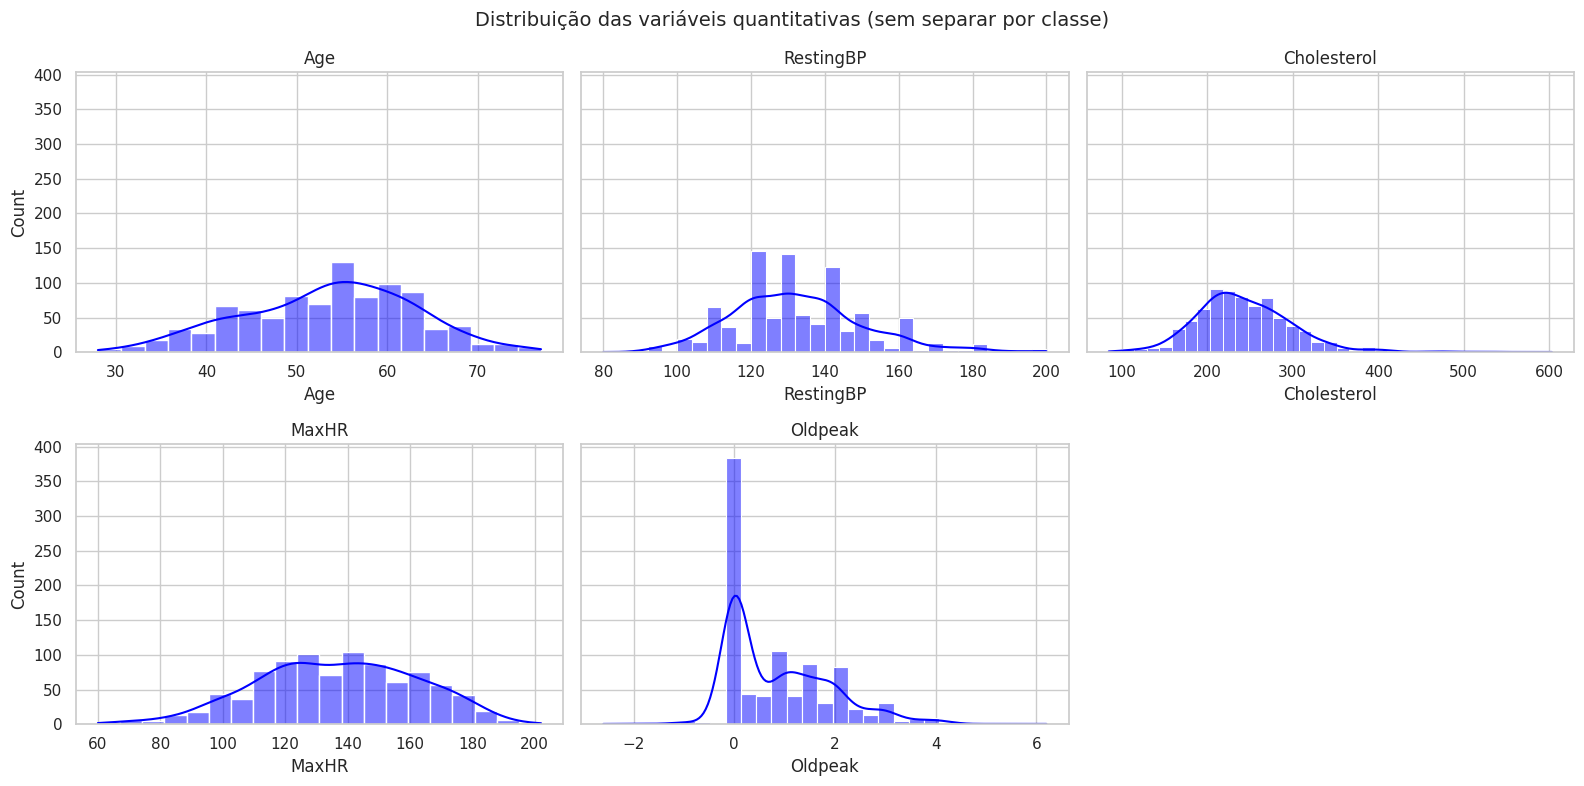

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das variáveis quantitativas (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

O `histplot` descarta `NaN` sem avisar, então o histograma do colesterol está desenhado sobre 746 pacientes e não sobre 918.

`Oldpeak` tem aquele pico enorme em zero, que são os 368 pacientes sem depressão do segmento ST. Como o eixo Y é compartilhado, esse pico achata um pouco os outros painéis.

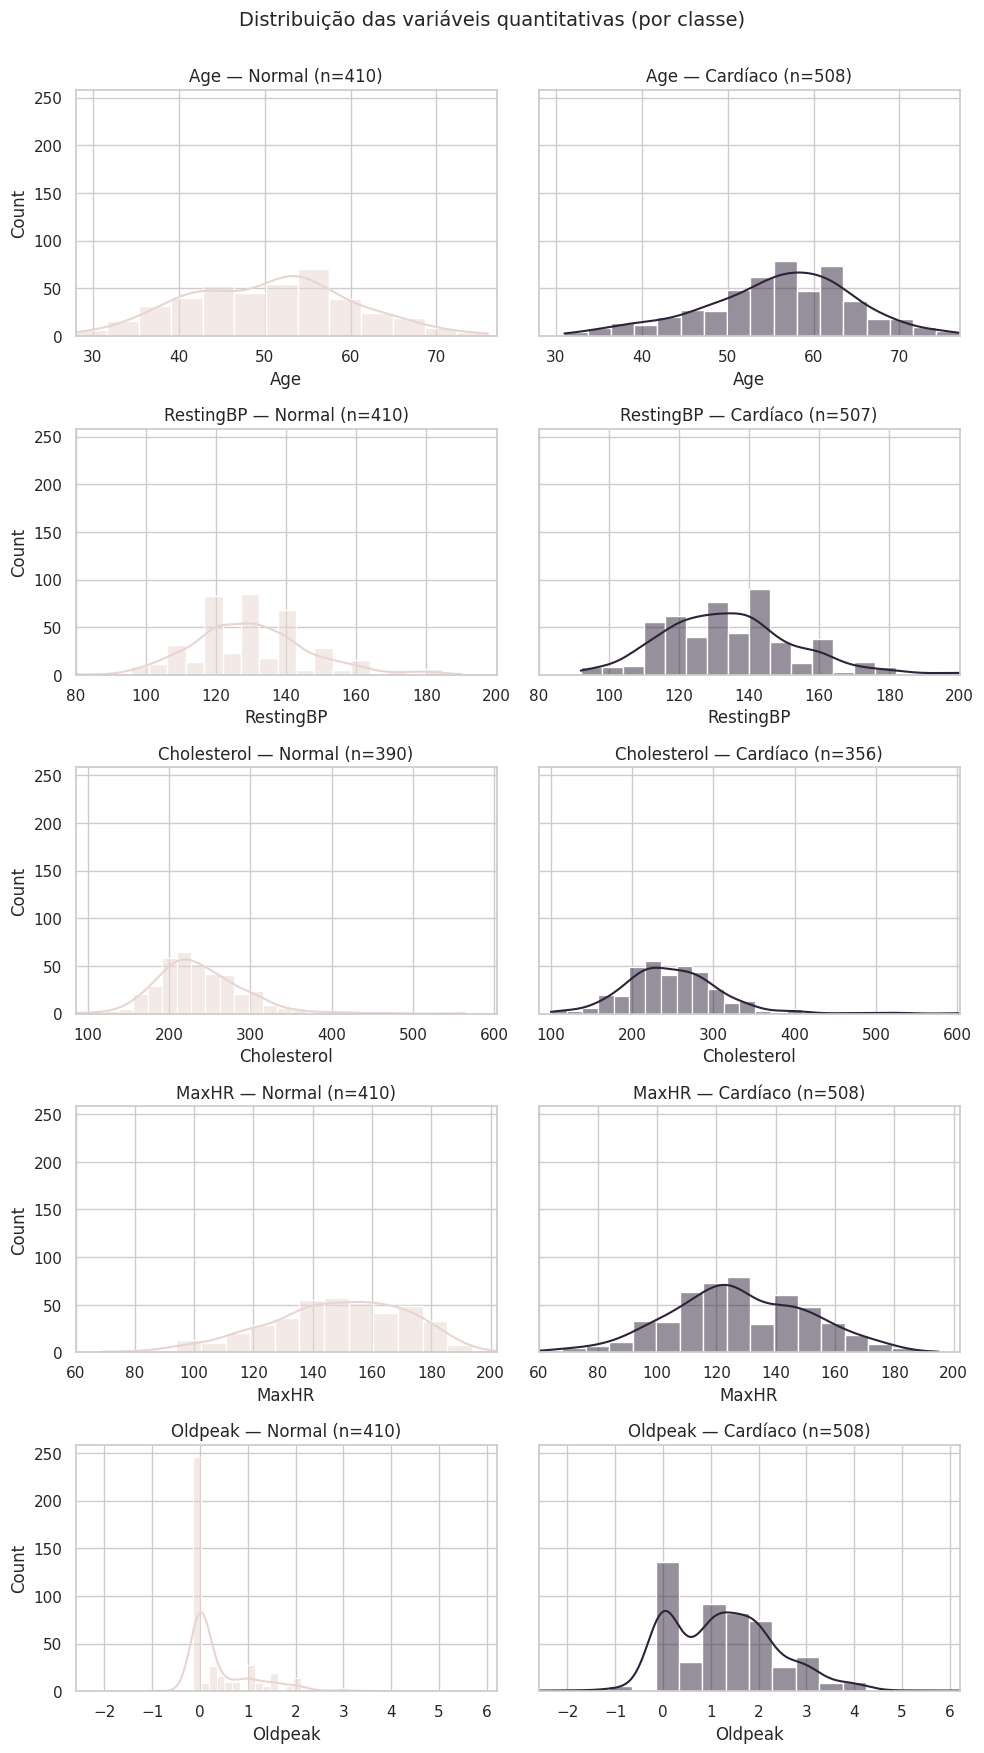

In [ ]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate([("Normal", COR_CONTEXTO), ("Cardíaco", COR_DESTAQUE)]):
        subset = df[df["doenca_cardiaca"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe} (n={subset[col].notna().sum()})")

fig.suptitle("Distribuição das variáveis quantitativas (por classe)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Pra discutir: alguma variável tem formato bem diferente entre as classes?**

`MaxHR` é a mais clara. O grupo Normal se concentra entre 140 e 180, e o Cardíaco desce para a faixa de 100 a 140. Pacientes com doença atingem frequência cardíaca máxima menor no esforço.

`Oldpeak` vai no sentido oposto. No grupo Normal quase tudo se acumula em zero, no Cardíaco a massa se espalha entre 1 e 3.

`Age` desloca menos, com o grupo Cardíaco concentrado acima dos 50 anos.

`RestingBP` e `Cholesterol` têm formatos parecidos nos dois painéis. Sozinhas, essas duas separam pouco.

#### Testes de aderência

Shapiro-Wilk — Cholesterol: estatística=0.9357, p-valor=2.152e-17
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


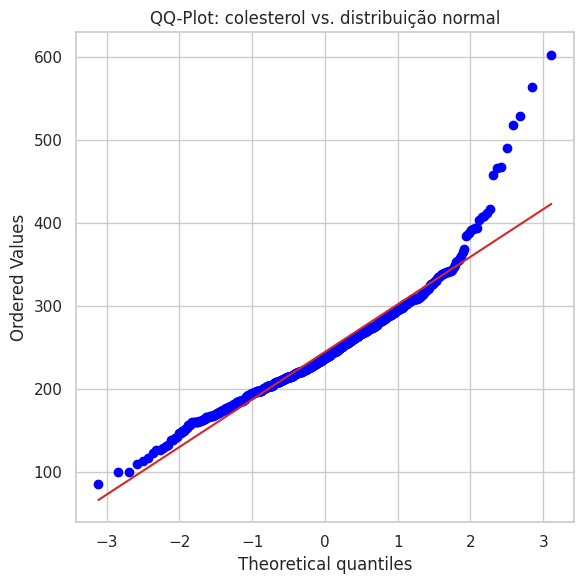

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df["Cholesterol"].dropna())
print(f"Shapiro-Wilk — Cholesterol: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["Cholesterol"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: colesterol vs. distribuição normal")
plt.tight_layout()
plt.show()

Não segue. A estatística deu 0,9357 com p-valor de 2,2 × 10⁻¹⁷.

**Como ler o QQ-plot:** se os pontos seguissem a reta vermelha de perto, a variável seria normal. Aqui eles acompanham bem no meio e escapam para cima no canto superior direito, o que indica cauda direita pesada. São os pacientes com colesterol muito alto.

O `.dropna()` está fazendo trabalho pesado nesse teste. Ele tira os 172 valores que eu converti, então o teste roda só sobre medições reais. Antes da conversão, o QQ-plot tinha uma linha horizontal de pontos em zero na parte de baixo, coisa que nenhuma distribuição contínua produz.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                               "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Age,0.9910,0.000022,True
RestingBP,0.9713,0.000000,True
Cholesterol,0.9357,0.000000,True
MaxHR,0.9927,0.000168,True
Oldpeak,0.8599,0.000000,True


Todas as cinco rejeitam normalidade.


#### ECDF

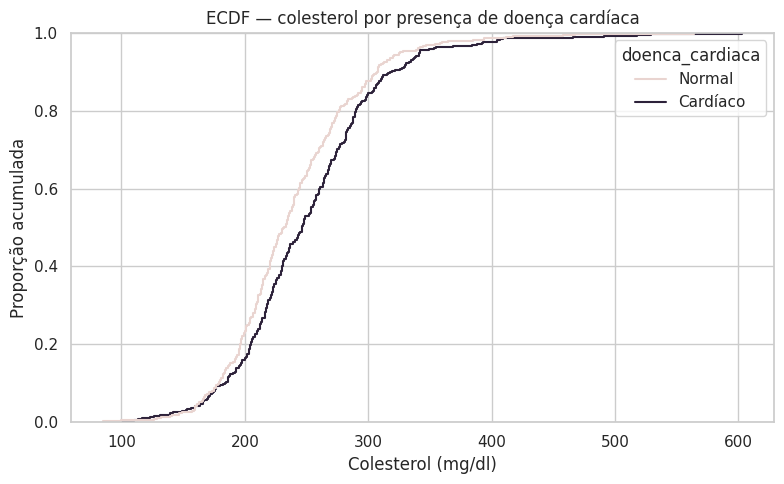

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Cholesterol", hue="doenca_cardiaca",
             palette={"Normal": COR_CONTEXTO, "Cardíaco": COR_DESTAQUE})
plt.title("ECDF — colesterol por presença de doença cardíaca")
plt.xlabel("Colesterol (mg/dl)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** a altura da curva em cada ponto diz que fração daquele grupo tem colesterol até ali. A leitura que interessa é a distância vertical entre as duas.

As curvas caminham próximas na maior parte do gráfico, com a roxa (Cardíaco) um pouco à direita da rosa a partir de uns 230. Ou seja, o grupo com doença tem colesterol levemente mais alto, mas a diferença é pequena.

Antes de eu converter os zeros esse gráfico tinha outra cara: a curva do grupo Cardíaco pulava direto para 0,30 em colesterol zero, e a do Normal para 0,06. Era a ausência sendo desenhada como se fosse um valor.

### Métricas de tendência central

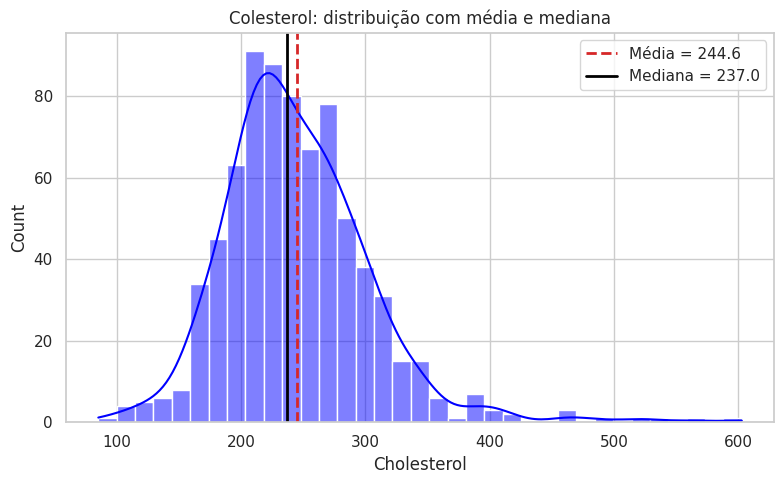

In [ ]:
media_chol = df["Cholesterol"].mean()
mediana_chol = df["Cholesterol"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Cholesterol", kde=True, color=COR_NEUTRA)
plt.axvline(media_chol, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_chol:.1f}")
plt.axvline(mediana_chol, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_chol:.1f}")
plt.title("Colesterol: distribuição com média e mediana")
plt.legend()
plt.tight_layout()
plt.show()

Média 244,6 e mediana 237,0. A média está acima da mediana, que é o padrão de uma distribuição com cauda à direita: os poucos pacientes com colesterol muito alto puxam a média para cima, e a mediana não se mexe.


Antes da correção, esse mesmo gráfico mostrava média 198,8 contra mediana 223,0, com a média **abaixo** da mediana. Os zeros invertiam a relação entre as duas.

### Dispersão

,var,std,IQR
Age,88.97,9.43,13.00
RestingBP,323.99,18.00,20.00
Cholesterol,3499.14,59.15,67.75
MaxHR,648.23,25.46,36.00
Oldpeak,1.14,1.07,1.50


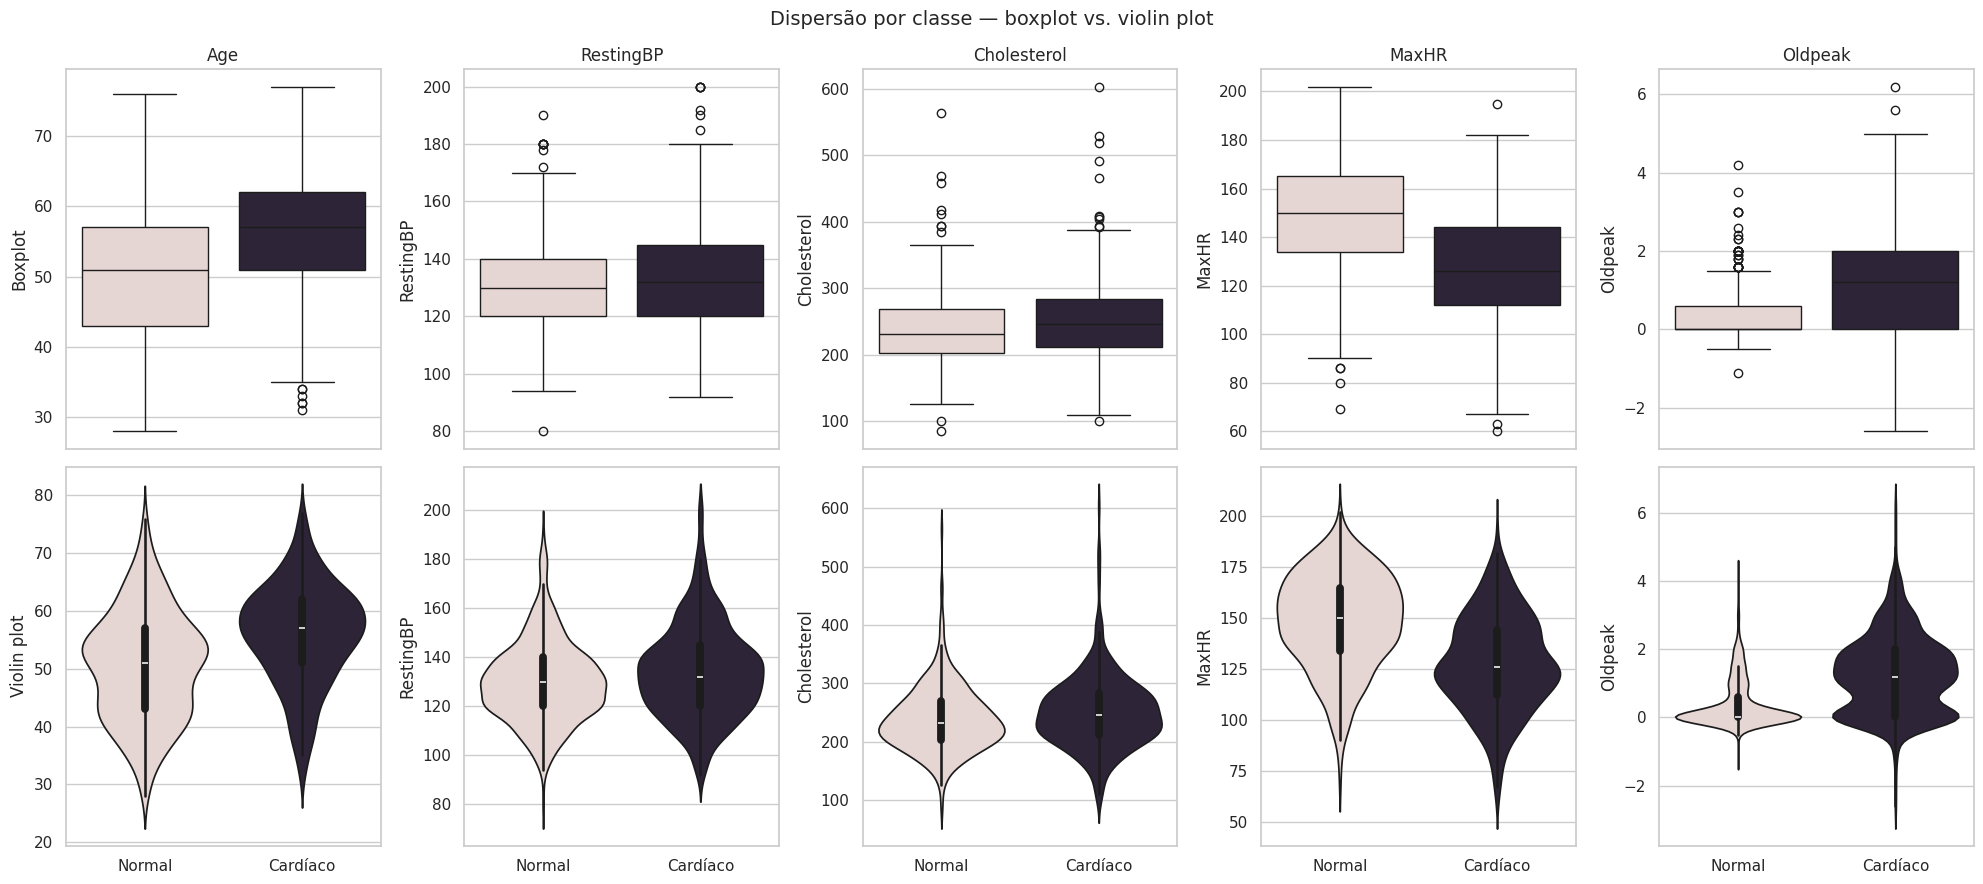

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
display(dispersao.round(2))

palette_classe = {"Normal": COR_CONTEXTO, "Cardíaco": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="doenca_cardiaca", y=col, hue="doenca_cardiaca",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="doenca_cardiaca", y=col, hue="doenca_cardiaca",
                   palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por classe — boxplot vs. violin plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir: alguma caixa (IQR) é nitidamente diferente entre as classes?**

`MaxHR` é a mais forte. A caixa do grupo Normal vai de 134 a 165 com mediana 150, e a do Cardíaco vai de 112 a 144 com mediana 126. As duas quase não se sobrepõem.

`Oldpeak` vem logo atrás. O grupo Normal tem caixa de 0 a 0,6 com mediana 0, e o Cardíaco tem caixa de 0 a 2,0 com mediana 1,2. O violin plot mostra isso melhor que o boxplot: no Normal a densidade é um pico único em zero, no Cardíaco ela se espalha.

`Age` desloca de forma moderada, com a caixa do Cardíaco (51 a 62) acima da do Normal (43 a 57).

`RestingBP` (mediana 130 contra 132) e `Cholesterol` (231,5 contra 246) têm caixas bem sobrepostas.


## 4. Tratamento de dados ausentes e outliers


### Detecção de outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_validos = df[col].notna().sum()
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_validos": n_validos,
        "n_outliers": n_outliers,
        "%_outliers": round(100 * n_outliers / n_validos, 2),
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_validos,n_outliers,%_outliers
Age,27.50,79.50,918.0,0.0,0.00
RestingBP,90.00,170.00,917.0,27.0,2.94
Cholesterol,105.62,376.62,746.0,23.0,3.08
MaxHR,66.00,210.00,918.0,2.0,0.22
Oldpeak,-2.25,3.75,918.0,16.0,1.74


Acrescentei `n_validos` e o percentual. Como as colunas têm números diferentes de observações válidas, dizer "23 outliers" sem dizer sobre quantos seria enganoso.

`Age` não tem nenhum outlier, `MaxHR` tem 2 (0,22%), `Oldpeak` tem 16 (1,74%), `RestingBP` tem 27 (2,94%) e `Cholesterol` tem 23 (3,08%). Nenhuma coluna passa de 4%.

Antes da correção da seção 2 esse mesmo código acusava 183 outliers no colesterol, quase 20% da base. Dos 183, 172 eram os zeros. A correção resolveu sozinha a maior parte do que parecia problema de outlier.

### Visualizando os outliers

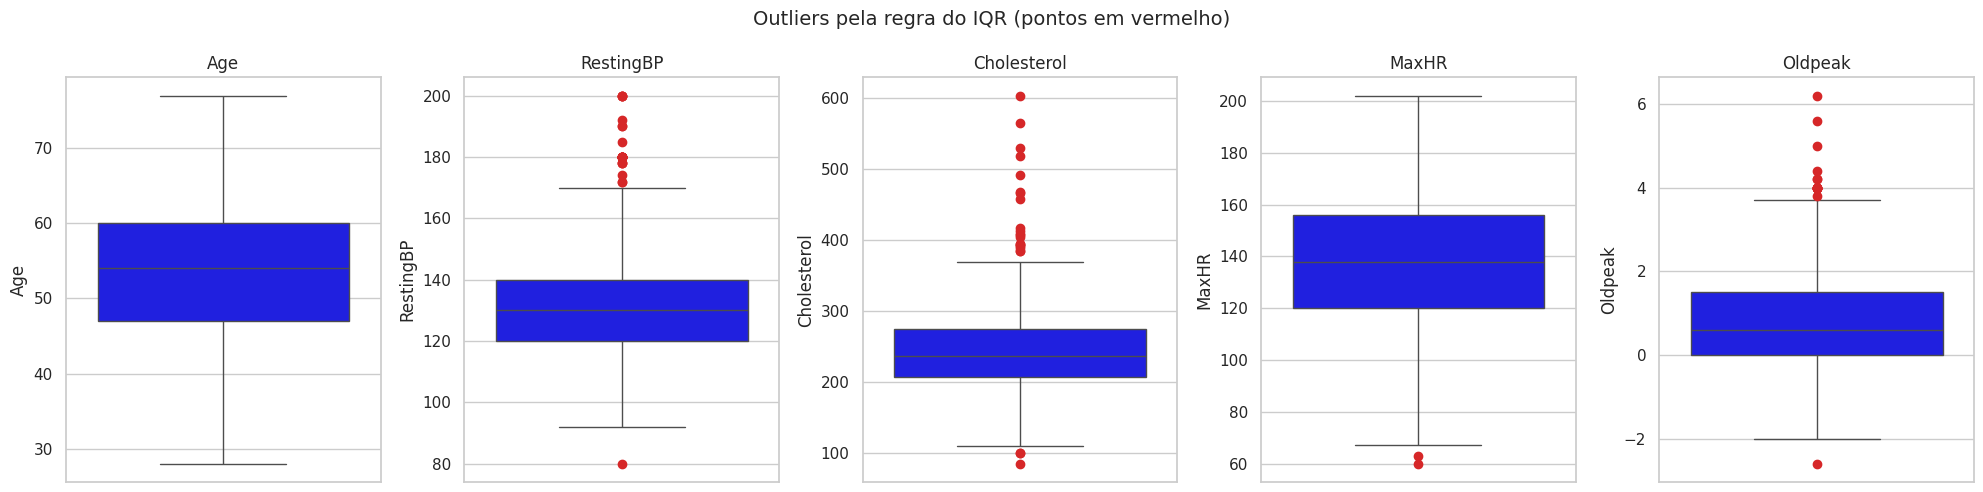

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:**
| Tipo | Cenário | O que fazer |
|---|---|---|
| Estatístico | Legítimo | Manter ou transformar |
| De domínio | Viola regra de negócio ou condição física | Investigar |
| Erros de dados | Falhas | Corrigir se possível, remover como última opção |

O meu dataset teve dois desses tipos ao mesmo tempo, e na mesma coluna.

Os zeros de `Cholesterol` e `RestingBP` são **erro de dados**, ou outlier de domínio, porque violam uma condição física. O tratamento recomendado é corrigir, e foi o que fiz ao recodificar como ausentes em vez de apagar as linhas.

O que sobrou depois disso é **estatístico**: 20 pacientes com colesterol acima de 376, chegando a 603; 26 com pressão acima de 170, chegando a 200; 16 com `Oldpeak` acima de 3,75; e dois com `MaxHR` de 60 e 63. Todos plausíveis clinicamente, ainda que raros. Provavelmente são os pacientes de maior risco da base, que é exatamente a informação que eu não quero jogar fora. Decisão: manter.

Um detalhe do `Oldpeak`: ele tem 13 valores negativos, com mínimo de -2,6. Isso não é erro de digitação. `Oldpeak` mede depressão do segmento ST, e valor negativo significa elevação, que é fisiologicamente possível e clinicamente relevante.


### Decidindo o tratamento dos dados ausentes

Em sala, o mecanismo dos ausentes era MAR ou MCAR e o volume era pequeno (umas poucas linhas em 303), então remover as linhas foi a decisão pragmática. O risco de viés era baixo e o custo de perder 2% dos dados também.

No meu dataset só metade disso vale.

`RestingBP` tem 1 ausente em 918. Aí sim o argumento é o mesmo e eu removo a linha.

`Cholesterol` tem 172, que é 18,74% da base, e o teste da seção 2 mostrou que a ausência está fortemente associada ao desfecho (88,4% contra 47,7%, p ≈ 10⁻²²). Remover essas linhas jogaria fora quase um quinto do dataset e, pior, jogaria fora um grupo específico de pacientes. A amostra que sobrasse deixaria de representar a original. Seria trocar um problema de dado faltante por um problema de viés de seleção.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()

df = df.dropna(subset=["RestingBP"]).reset_index(drop=True)

df["Cholesterol_imputado"] = df["Cholesterol"].isna()
mediana_chol = df["Cholesterol"].median()
df["Cholesterol"] = df["Cholesterol"].fillna(mediana_chol)

linhas_depois = df.shape[0]
print(f"Linhas antes: {linhas_antes} | depois: {linhas_depois} | removidas: {linhas_antes - linhas_depois}")
print(f"Colesterol imputado pela mediana ({mediana_chol:.1f}) em {df['Cholesterol_imputado'].sum()} linhas")
print(f"Ausentes restantes: {df.isna().sum().sum()}")

Linhas antes: 918 | depois: 917 | removidas: 1
Colesterol imputado pela mediana (237.0) em 171 linhas
Ausentes restantes: 0


Sobraram 917 linhas, com 171 valores de colesterol imputados em 237,0 e nenhum ausente.

### Decidindo o tratamento dos outliers

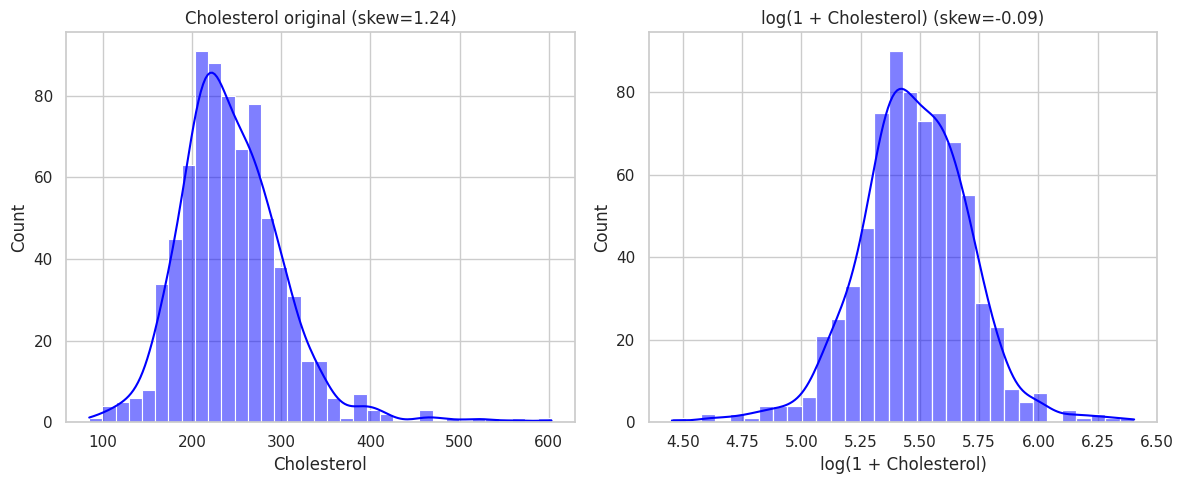

In [ ]:
chol_real = df.loc[~df["Cholesterol_imputado"], "Cholesterol"]
chol_real_log = np.log1p(chol_real)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(x=chol_real, kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Cholesterol original (skew={chol_real.skew():.2f})")
axes[0].set_xlabel("Cholesterol")

sns.histplot(x=chol_real_log, kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Cholesterol) (skew={chol_real_log.skew():.2f})")
axes[1].set_xlabel("log(1 + Cholesterol)")

plt.tight_layout()
plt.show()

**Pra discutir: a transformação reduziu a assimetria?**

Reduziu bastante. A skewness saiu de 1,24 para -0,09, ou seja, a distribuição ficou praticamente simétrica.


## 5. Estatística descritiva pt. 2


In [ ]:
def descritiva(dados):
    d = dados[VARS_QUANT].describe().T
    d["skewness"] = dados[VARS_QUANT].skew()
    d["kurtosis"] = dados[VARS_QUANT].kurtosis()
    return d

desc_antes = descritiva(df_antes)
desc_depois = descritiva(df)

display(desc_antes[["count", "mean", "50%", "std", "skewness", "kurtosis"]].round(2))
display(desc_depois[["count", "mean", "50%", "std", "skewness", "kurtosis"]].round(2))

,count,mean,50%,std,skewness,kurtosis
Age,918.0,53.51,54.0,9.43,-0.20,-0.39
RestingBP,917.0,132.54,130.0,18.00,0.61,0.79
Cholesterol,746.0,244.64,237.0,59.15,1.24,4.53
MaxHR,918.0,136.81,138.0,25.46,-0.14,-0.45
Oldpeak,918.0,0.89,0.6,1.07,1.02,1.20


,count,mean,50%,std,skewness,kurtosis
Age,917.0,53.51,54.0,9.44,-0.20,-0.39
RestingBP,917.0,132.54,130.0,18.00,0.61,0.79
Cholesterol,917.0,243.21,237.0,53.43,1.45,6.34
MaxHR,917.0,136.79,138.0,25.47,-0.14,-0.45
Oldpeak,917.0,0.89,0.6,1.07,1.02,1.20


### Comparando "antes" e "depois"

In [ ]:
comparacao = pd.DataFrame({
    "std_antes": desc_antes["std"],
    "std_depois": desc_depois["std"],
    "skewness_antes": desc_antes["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc_antes["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_std"] = (comparacao["std_depois"] - comparacao["std_antes"]).round(3)
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,std_antes,std_depois,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_std,delta_skewness,delta_kurtosis
Age,9.433,9.438,-0.196,-0.195,-0.386,-0.389,0.005,0.001,-0.003
RestingBP,18.000,18.000,0.607,0.607,0.792,0.792,0.000,0.000,0.000
Cholesterol,59.154,53.430,1.239,1.446,4.529,6.341,-5.723,0.207,1.812
MaxHR,25.460,25.467,-0.144,-0.142,-0.448,-0.449,0.007,0.002,-0.001
Oldpeak,1.067,1.067,1.023,1.025,1.203,1.204,0.000,0.002,0.001


**Pra discutir: os valores mudaram muito?**

Mudaram em uma variável só. `Age`, `RestingBP`, `MaxHR` e `Oldpeak` têm deltas praticamente zerados (na casa do 0,001), o que confirma que o tratamento foi cirúrgico e não atropelou a base.

`Cholesterol` mudou: o desvio padrão caiu de 59,15 para 53,43, a skewness subiu de 1,24 para 1,45 e a curtose subiu de 4,53 para 6,34.

**O colesterol ainda rejeita normalidade?**

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["Cholesterol"])

print(f"Shapiro-Wilk (antes)  — Cholesterol: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — Cholesterol: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — Cholesterol: estatística=0.9357, p-valor=2.152e-17
Shapiro-Wilk (depois) — Cholesterol: estatística=0.9071, p-valor=3.383e-23


Continua rejeitando, e a estatística piorou: foi de 0,9357 para 0,9071.


**Antes e depois lado a lado**

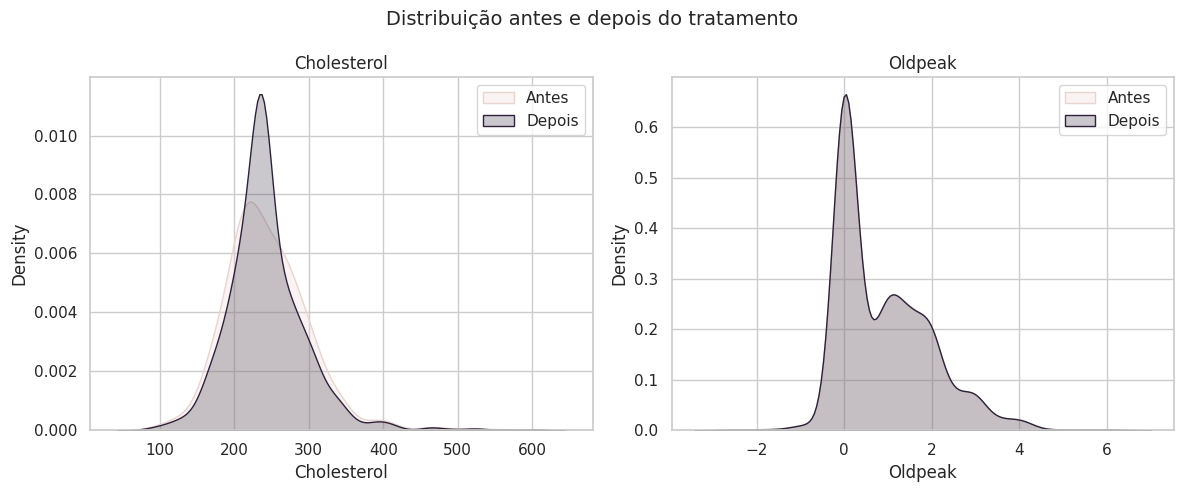

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["Cholesterol", "Oldpeak"]):
    sns.kdeplot(df_antes[col].dropna(), color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição antes e depois do tratamento", fontsize=14)
plt.tight_layout()
plt.show()

Escolhi uma variável que recebeu tratamento (`Cholesterol`) e uma que não recebeu (`Oldpeak`), para ver os dois casos.

Em `Oldpeak` as curvas se sobrepõem por completo, como esperado. Em `Cholesterol` a curva "depois" tem um pico em 237 que não existia antes. Essa é a assinatura visual da imputação.


## 6. Princípio relacional

### Análise de variáveis qualitativas

#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- Sex ---
     absoluta  relativa
Sex                    
M         724      0.79
F         193      0.21

--- ChestPainType ---
               absoluta  relativa
ChestPainType                    
ASY                 496     0.541
NAP                 202     0.220
ATA                 173     0.189
TA                   46     0.050

--- FastingBS ---
           absoluta  relativa
FastingBS                    
0               703     0.767
1               214     0.233

--- RestingECG ---
            absoluta  relativa
RestingECG                    
Normal           551     0.601
LVH              188     0.205
ST               178     0.194

--- ExerciseAngina ---
                absoluta  relativa
ExerciseAngina                    
N                    546     0.595
Y                    371     0.405

--- ST_Slope ---
          absoluta  relativa
ST_Slope                    
Flat           459     0.501
Up             395     0.431
Down            63     0.069


#### Visualizando as frequências

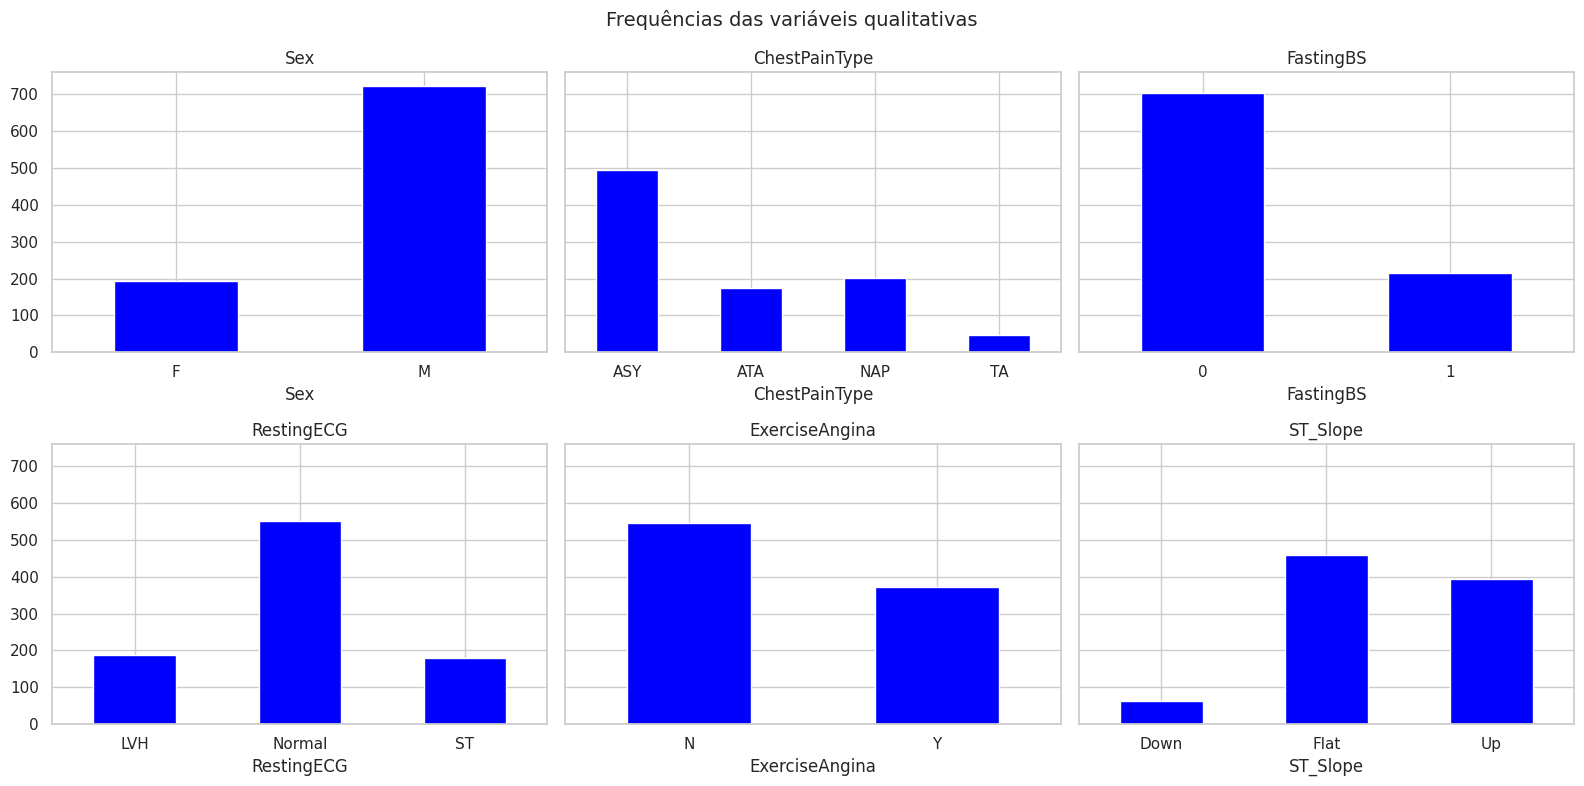

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

for ax in axes[len(VARS_QUALI):]:
    ax.axis("off")

fig.suptitle("Frequências das variáveis qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir: alguma qualitativa está bem desbalanceada?**

`Sex` é a mais desbalanceada: 724 homens contra 193 mulheres, ou seja, 79% contra 21%.

`ChestPainType` tem 496 pacientes em ASY (54,1%) e só 46 em TA (5%).

`FastingBS` tem 703 em zero contra 214 em um, e `RestingECG` tem 551 em Normal contra 188 e 178 nas outras duas.

`ExerciseAngina` é a mais equilibrada, com 546 contra 371.

Isso tem consequência prática: categoria com pouco caso gera casa com contagem baixa na tabela de contingência, e o qui-quadrado perde confiabilidade quando a frequência esperada de alguma casa fica abaixo de 5.

#### Desbalanceamento entre classes

- **Razão de desbalanceamento**: número da classe majoritária dividido pelo da minoritária. Quanto maior, mais desbalanceado.
- **Entropia de Shannon normalizada**: 1 é perfeitamente balanceado, 0 é uma classe dominando tudo.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["doenca_cardiaca"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
Sex,2.0,3.75,0.742
ChestPainType,4.0,10.78,0.815
FastingBS,2.0,3.29,0.784
RestingECG,3.0,3.10,0.864
ExerciseAngina,2.0,1.47,0.974
ST_Slope,3.0,7.29,0.813
doenca_cardiaca,2.0,1.24,0.992


**Pra discutir: alguma variável tem entropia perto de 0? E o alvo está balanceado?**

Nenhuma chega perto de 0, mas a razão de desbalanceamento separa bem as coisas. `ChestPainType` tem razão 10,78 e `ST_Slope` tem 7,29, as duas maiores, puxadas pelas categorias TA (46 casos) e Down (63 casos).

`Sex` tem razão 3,75 e entropia 0,742, a menor entropia da tabela entre as variáveis de duas categorias.

O alvo `doenca_cardiaca` tem razão 1,24 e entropia 0,992, praticamente balanceado. Boa notícia: não preciso de reamostragem nem de correção antes da análise bivariada, e as proporções dos cruzamentos podem ser lidas direto.

### Análise bivariada

#### Quantitativa x quantitativa: correlação

São três medidas de correlação: Pearson (linear, sensível a outlier, pede normalidade), Spearman e Kendall (relação monotônica, não pedem normalidade).

Como nenhuma das minhas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura. Calculei as três para comparar.

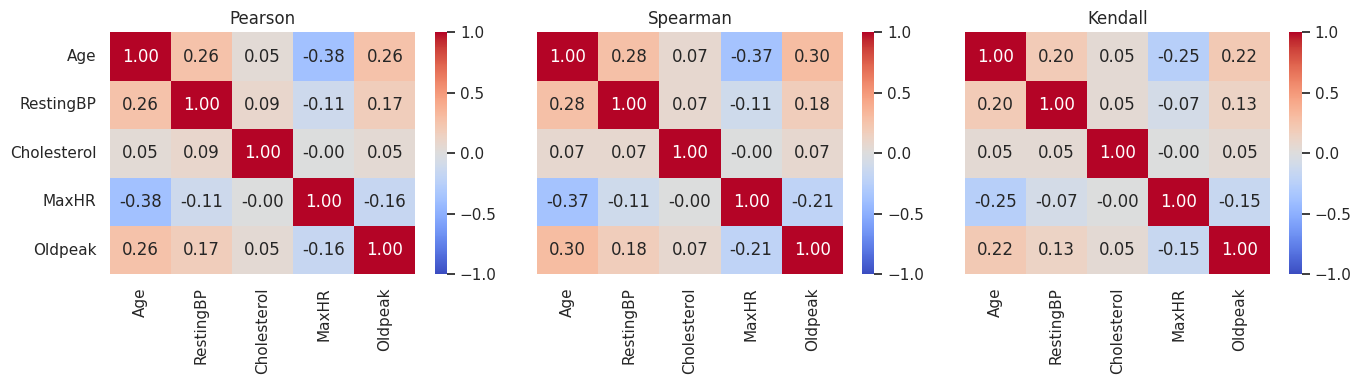

In [ ]:
corr_pearson  = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall  = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Kendall")
plt.tight_layout()
plt.show()

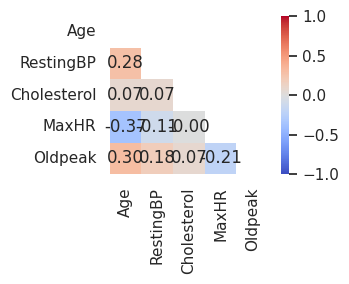

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1)
plt.grid(False)
plt.tight_layout()
plt.show()

**Pra discutir: Pearson e Spearman divergem em algum par?**

Não de forma relevante. A maior diferença é em `MaxHR` x `Oldpeak`, que dá -0,16 em Pearson e -0,21 em Spearman, e em `Age` x `Oldpeak`, 0,26 contra 0,30. São diferenças pequenas, o que sugere que as relações aqui são aproximadamente lineares quando existem.

As correlações mais fortes são todas fracas em termos absolutos: `Age` x `MaxHR` (-0,37), `Age` x `Oldpeak` (0,30) e `Age` x `RestingBP` (0,28).

In [ ]:
df_real = df.loc[~df["Cholesterol_imputado"]]

comparacao_corr = pd.DataFrame({
    "com imputados": df[VARS_QUANT].corr(method="spearman")["Cholesterol"],
    "só medidos":    df_real[VARS_QUANT].corr(method="spearman")["Cholesterol"],
}).round(3)
comparacao_corr

,com imputados,só medidos
Age,0.070,0.083
RestingBP,0.073,0.092
Cholesterol,1.000,1.000
MaxHR,-0.001,-0.003
Oldpeak,0.072,0.086


A diferença existe mas é pequena: com `Age` vai de 0,070 para 0,083, com `RestingBP` de 0,073 para 0,092, com `Oldpeak` de 0,072 para 0,086. Todos continuam sendo correlações muito fracas.

Então a conclusão se mantém dos dois jeitos: o colesterol tem pouca relação linear ou monotônica com as outras quantitativas deste dataset.

#### Dispersão entre duas quantitativas

Escolhi `Age` x `MaxHR` por um motivo de domínio, não só estatístico: existe uma relação fisiológica conhecida entre idade e frequência cardíaca máxima, já que a FC máxima tende a cair com a idade. Também é o par com a maior correlação da tabela (-0,37), então estatística e domínio apontaram para o mesmo lugar.

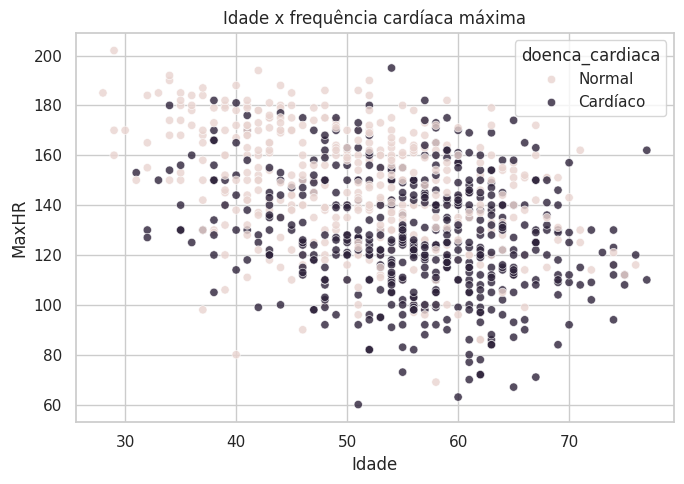

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Age", y="MaxHR", hue="doenca_cardiaca",
                palette={"Normal": COR_CONTEXTO, "Cardíaco": COR_DESTAQUE}, alpha=0.8)
plt.title("Idade x frequência cardíaca máxima")
plt.xlabel("Idade")
plt.ylabel("MaxHR")
plt.tight_layout()
plt.show()

**Pra discutir: a tendência aparece? As classes ocupam regiões diferentes?**

A tendência de queda aparece, ainda que com bastante dispersão em volta, o que é coerente com uma correlação de -0,37.

As classes não formam blocos separados, mas se distribuem de maneira desigual. Os pontos roxos se concentram mais na metade de baixo do gráfico, ou seja, pacientes com doença têm FC máxima menor mesmo comparando idades parecidas. Isso quer dizer que `MaxHR` carrega informação sobre o desfecho que não é só reflexo da idade.

#### Quantitativa x qualitativa: comparando grupos

T-Test (2 grupos) e ANOVA (3 ou mais) são os testes paramétricos para comparar uma quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Como nenhuma das minhas quantitativas passou no Shapiro-Wilk, o correto é usar os equivalentes não-paramétricos: Mann-Whitney U no lugar do T-Test e Kruskal-Wallis no lugar da ANOVA.

In [ ]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_normal   = df.loc[df["doenca_cardiaca"] == "Normal", col]
    grupo_cardiaco = df.loc[df["doenca_cardiaca"] == "Cardíaco", col]

    stat_t, p_t = stats.ttest_ind(grupo_normal, grupo_cardiaco, equal_var=False)  # Welch
    stat_u, p_u = stats.mannwhitneyu(grupo_normal, grupo_cardiaco)

    resultados_comparacao.append({
        "variavel": col,
        "mediana_normal": grupo_normal.median(),
        "mediana_cardiaco": grupo_cardiaco.median(),
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,mediana_normal,mediana_cardiaco,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,,,
Age,51.0,57.0,0.00000,0.00000,True
RestingBP,130.0,132.0,0.00028,0.00046,True
Cholesterol,235.0,237.0,0.02126,0.00258,True
MaxHR,150.0,126.0,0.00000,0.00000,True
Oldpeak,0.0,1.2,0.00000,0.00000,True


**Pra discutir: os dois testes concordam?**

Concordam nas cinco variáveis. Todas deram diferença significativa entre os grupos, mas com forças bem diferentes.

`Oldpeak` (p ≈ 9 × 10⁻³⁷) e `MaxHR` (p ≈ 1 × 10⁻³⁴) são as mais fortes, seguidas de `Age` (p ≈ 2 × 10⁻¹⁸). Nessas três a diferença de mediana também é grande: 0,0 contra 1,2 em `Oldpeak` e 150 contra 126 em `MaxHR`.

`RestingBP` (p ≈ 0,0005) e `Cholesterol` (p ≈ 0,003) também passam, mas com medianas quase iguais (130 contra 132, e 235 contra 237). Aqui aparece a mesma armadilha do Shapiro-Wilk: com 917 observações, diferença pequena vira significativa. Significância estatística não é o mesmo que relevância prática, e olhar a mediana junto com o p-valor evita essa confusão.

Uma ressalva sobre o colesterol: esse teste inclui os 171 valores imputados, quase todos do grupo Cardíaco, todos iguais a 237. Rodando só com as medições reais, a diferença de mediana é 231,5 contra 246,0 e o p-valor é 0,0017. A conclusão não muda, mas o número reportado deveria ser esse.

*Exemplo com 3 ou mais grupos: ANOVA contra Kruskal-Wallis*

`ChestPainType` tem quatro categorias: ASY (assintomático), ATA (angina atípica), NAP (dor não anginosa) e TA (angina típica).

ANOVA          — MaxHR entre categorias de ChestPainType: F=46.901, p=3.4088e-28
Kruskal-Wallis — MaxHR entre categorias de ChestPainType: H=125.808, p=4.3281e-27


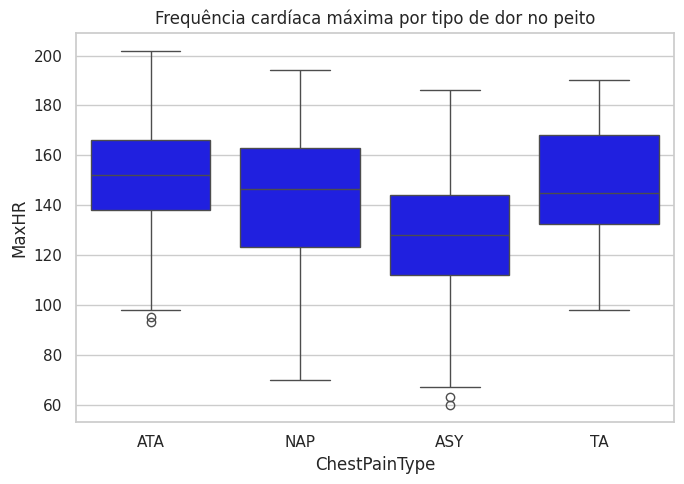

In [ ]:
grupos_cp = [grupo["MaxHR"].values for _, grupo in df.groupby("ChestPainType")]

stat_anova, p_anova = stats.f_oneway(*grupos_cp)
stat_kw, p_kw = stats.kruskal(*grupos_cp)

print(f"ANOVA          — MaxHR entre categorias de ChestPainType: F={stat_anova:.3f}, p={p_anova:.5g}")
print(f"Kruskal-Wallis — MaxHR entre categorias de ChestPainType: H={stat_kw:.3f}, p={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="ChestPainType", y="MaxHR", color=COR_NEUTRA)
plt.title("Frequência cardíaca máxima por tipo de dor no peito")
plt.tight_layout()
plt.show()

**Pra discutir: o Kruskal-Wallis concorda com a ANOVA?**

Concorda. ANOVA deu F = 46,9 com p ≈ 3 × 10⁻²⁸, e Kruskal-Wallis deu H = 125,8 com p ≈ 4 × 10⁻²⁷. Existe diferença em pelo menos uma categoria, e como `MaxHR` não é normal, o resultado que eu reporto é o do Kruskal-Wallis.

O boxplot mostra onde está a diferença: ASY tem mediana 128, enquanto ATA (152), NAP (146,5) e TA (145) ficam bem acima e parecidas entre si. O grupo assintomático é o que destoa.

E isso tem leitura clínica. ASY é a categoria mais frequente da base (496 de 917) e é a que mais concentra doença: 79% dos pacientes ASY têm diagnóstico positivo, contra 13,9% dos ATA. Paciente sem dor no peito característica não é paciente sem doença. É justamente o perfil que passa despercebido no exame clínico.

#### Qualitativa x qualitativa: qui-quadrado

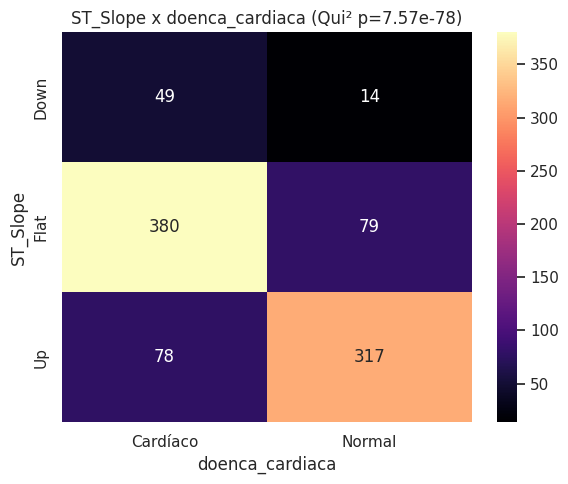

Qui-quadrado = 355.16 | gl = 2 | p-valor = 7.567e-78
Menor frequência esperada: 28.2
doenca_cardiaca  Cardíaco  Normal
ST_Slope                         
Down                 77.8    22.2
Flat                 82.8    17.2
Up                   19.7    80.3


In [ ]:
contingencia_st = pd.crosstab(df["ST_Slope"], df["doenca_cardiaca"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_st)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_st, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"ST_Slope x doenca_cardiaca (Qui² p={p_chi2:.3g})")
plt.tight_layout()
plt.show()

print(f"Qui-quadrado = {chi2:.2f} | gl = {gl} | p-valor = {p_chi2:.3e}")
print(f"Menor frequência esperada: {esperado.min():.1f}")
print((pd.crosstab(df["ST_Slope"], df["doenca_cardiaca"], normalize="index") * 100).round(1))

**Pra discutir: independentes ou associadas?**

Fortemente associadas. O qui-quadrado deu 355,16 com 2 graus de liberdade e p ≈ 8 × 10⁻⁷⁸, o menor p-valor de todo o notebook.

As proporções explicam o porquê: entre os pacientes com `ST_Slope = Up`, só 19,7% têm doença. Entre os `Flat`, são 82,8%, e entre os `Down`, 77,8%. A categoria praticamente inverte o prognóstico.

Também imprimi a menor frequência esperada, que deu 28,2. Como está bem acima de 5, o teste é válido. Essa checagem importa porque `Down` tem só 63 casos, e eu tinha anotado lá atrás que categoria pequena poderia invalidar o teste.

#### Avaliação de fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta comum em discussões de fairness é se a distribuição do desfecho se comporta igual em subgrupos de atributos sensíveis, no caso sexo e faixa etária. Se não se comporta, pode ser um padrão real ou um viés na coleta, e nos dois casos vale mapear antes de qualquer modelagem.

In [ ]:
df["sexo_label"] = df["Sex"].map({"F": "Feminino", "M": "Masculino"})
df["faixa_etaria"] = pd.cut(df["Age"], bins=[0, 45, 55, 65, 100],
                            labels=["<45", "45-54", "55-64", "65+"])

print("Desbalanceamento — sexo:")
print(metrica_desbalanceamento(df["sexo_label"]))
print("\nDesbalanceamento — faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

Desbalanceamento — sexo:
n_classes                 2.000
razao_desbalanceamento    3.750
entropia_normalizada      0.742
dtype: float64

Desbalanceamento — faixa etária:
n_classes                 4.000
razao_desbalanceamento    3.950
entropia_normalizada      0.924
dtype: float64


doenca_cardiaca,Cardíaco,Normal
sexo_label,,
Feminino,25.9,74.1
Masculino,63.1,36.9


doenca_cardiaca,Cardíaco,Normal
faixa_etaria,,
<45,31.1,68.9
45-54,50.5,49.5
55-64,71.0,29.0
65+,69.5,30.5


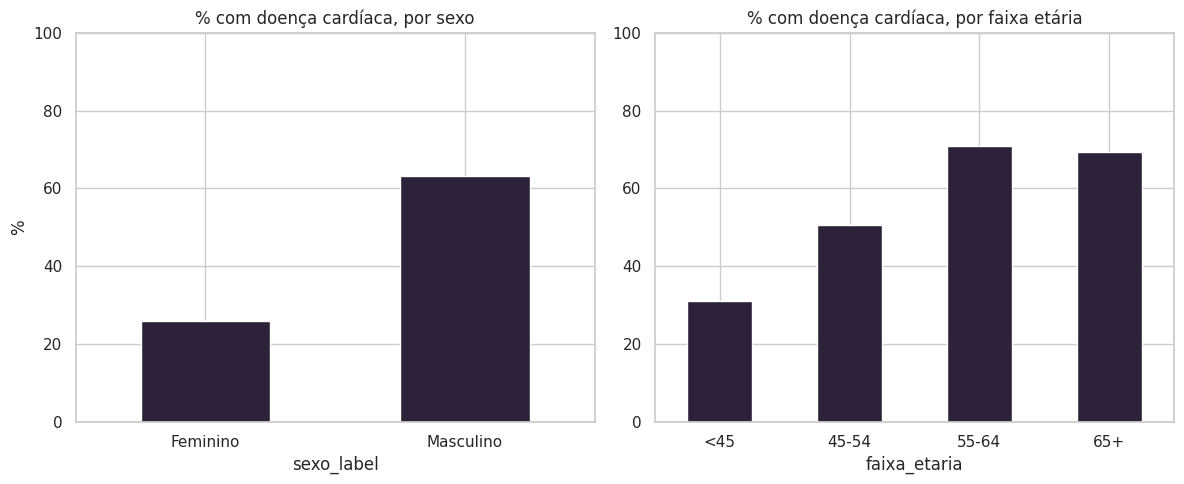

In [ ]:
prop_por_sexo  = (pd.crosstab(df["sexo_label"], df["doenca_cardiaca"], normalize="index") * 100).round(1)
prop_por_faixa = (pd.crosstab(df["faixa_etaria"], df["doenca_cardiaca"], normalize="index") * 100).round(1)

display(prop_por_sexo)
display(prop_por_faixa)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_sexo["Cardíaco"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("% com doença cardíaca, por sexo")
axes[0].set_ylabel("%")
axes[0].set_ylim(0, 100)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa["Cardíaco"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("% com doença cardíaca, por faixa etária")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir: a proporção de diagnóstico positivo varia entre os grupos?**

Varia muito nos dois casos.

Por sexo: 63,1% dos homens têm diagnóstico positivo contra 25,9% das mulheres. É uma diferença de quase 40 pontos, numa base que já tem 724 homens contra 193 mulheres.

Por faixa etária: 31,1% abaixo de 45 anos, 50,5% entre 45 e 54, 71,0% entre 55 e 64 e 69,5% acima de 65. O crescimento é claro até os 64 anos e depois estabiliza.

A faixa etária tem explicação clínica documentada: risco cardíaco aumenta com a idade, e o padrão crescente é o que se esperaria.

O sexo é mais delicado. A diferença pode ser risco real, pode ser efeito de quem foi encaminhado para o exame, ou as duas coisas. Existe literatura mostrando que sintoma cardíaco em mulher é historicamente subdiagnosticado, e isso produziria exatamente esse padrão nos dados mesmo sem o risco real ser menor. Duas hipóteses opostas geram a mesma tabela.

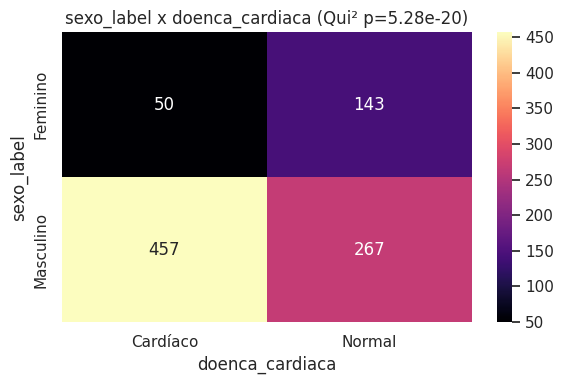

sexo_label: Qui² = 83.87 | gl = 1 | p = 5.281e-20 | menor esperado = 86.3


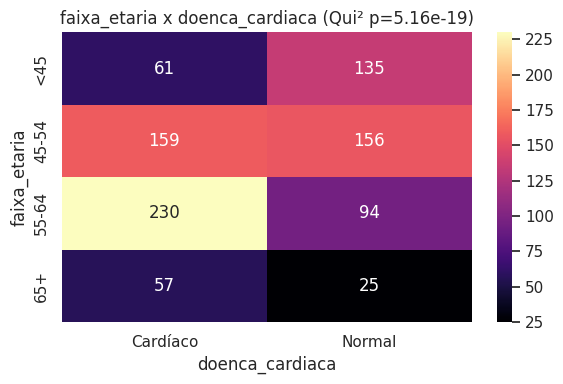

faixa_etaria: Qui² = 88.27 | gl = 3 | p = 5.157e-19 | menor esperado = 36.7


In [ ]:
for atributo in ["sexo_label", "faixa_etaria"]:
    contingencia = pd.crosstab(df[atributo], df["doenca_cardiaca"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x doenca_cardiaca (Qui² p={p_valor:.3g})")
    plt.tight_layout()
    plt.show()
    print(f"{atributo}: Qui² = {chi2:.2f} | gl = {gl} | p = {p_valor:.3e} | menor esperado = {esperado.min():.1f}")

**Pra discutir: o qui-quadrado confirma a associação?**

Confirma nos dois. Sexo deu 83,87 com p ≈ 5 × 10⁻²⁰, e faixa etária deu 88,27 com p ≈ 5 × 10⁻¹⁹. As menores frequências esperadas são 86,3 e 36,7, as duas bem acima de 5, então os testes são válidos.

Mas confirmar associação não é explicar associação. O teste mede se a distribuição observada se afasta do que o acaso produziria, e só. No caso da idade a causa provável é fator de risco real. No caso do sexo pode ser viés de encaminhamento.


In [ ]:
print("Ausência de colesterol por sexo (%):")
print((df.groupby("sexo_label")["Cholesterol_imputado"].mean() * 100).round(1))

Ausência de colesterol por sexo (%):
sexo_label
Feminino      5.7
Masculino    22.1
Name: Cholesterol_imputado, dtype: float64


#### Outliers bivariados

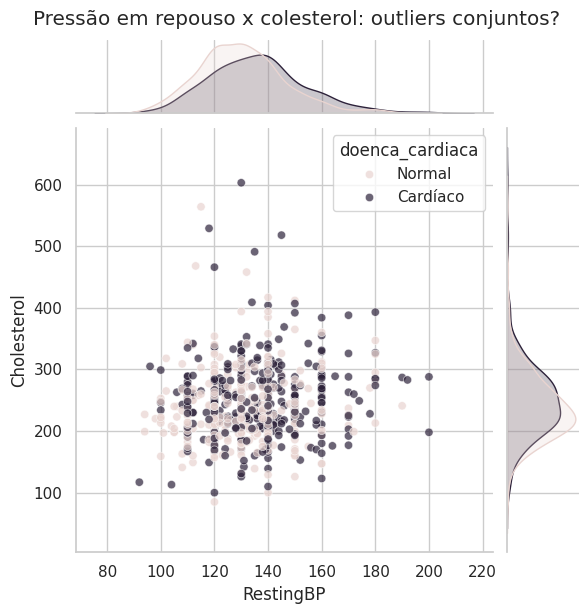

In [ ]:
sns.jointplot(data=df_real, x="RestingBP", y="Cholesterol", hue="doenca_cardiaca",
              palette={"Normal": COR_CONTEXTO, "Cardíaco": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Pressão em repouso x colesterol: outliers conjuntos?", y=1.02)
plt.show()


**Pra discutir: algum ponto se destaca aqui que não se destacava nos histogramas?**

Sim. Aparecem pacientes com pressão dentro da normalidade e colesterol acima de 500, e o oposto também, pressão perto de 200 com colesterol em torno de 200. Nenhum desses valores chamaria atenção sozinho, porque cada um está dentro de uma faixa aceitável na sua própria variável. O que é raro é a combinação.

É o argumento a favor de olhar pares mesmo depois de já ter inspecionado cada variável isoladamente.

#### Análise multivariada

##### Matriz de correlação

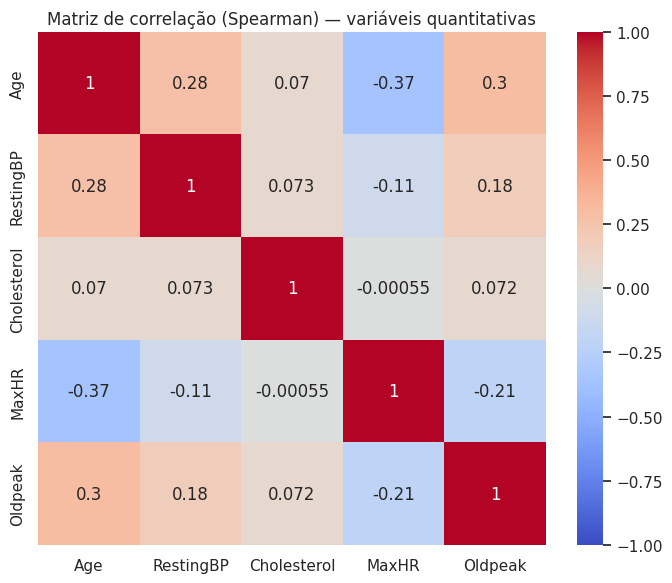

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlação (Spearman) — variáveis quantitativas")
plt.tight_layout()
plt.show()

Como interpretar: |r| abaixo de 0,3 é fraca, entre 0,3 e 0,7 é moderada, acima de 0,7 é forte.

Só três pares chegam a moderada, e por pouco: `Age` x `MaxHR` (-0,37), `Age` x `Oldpeak` (0,30) e `Age` x `RestingBP` (0,28). Todo o resto é fraco.

Nenhuma correlação chega perto de 0,7, então não tem redundância entre as variáveis. Isso é bom: cada uma carrega informação própria sobre o paciente, e nenhuma precisaria ser descartada por duplicar outra.

##### Correlograma

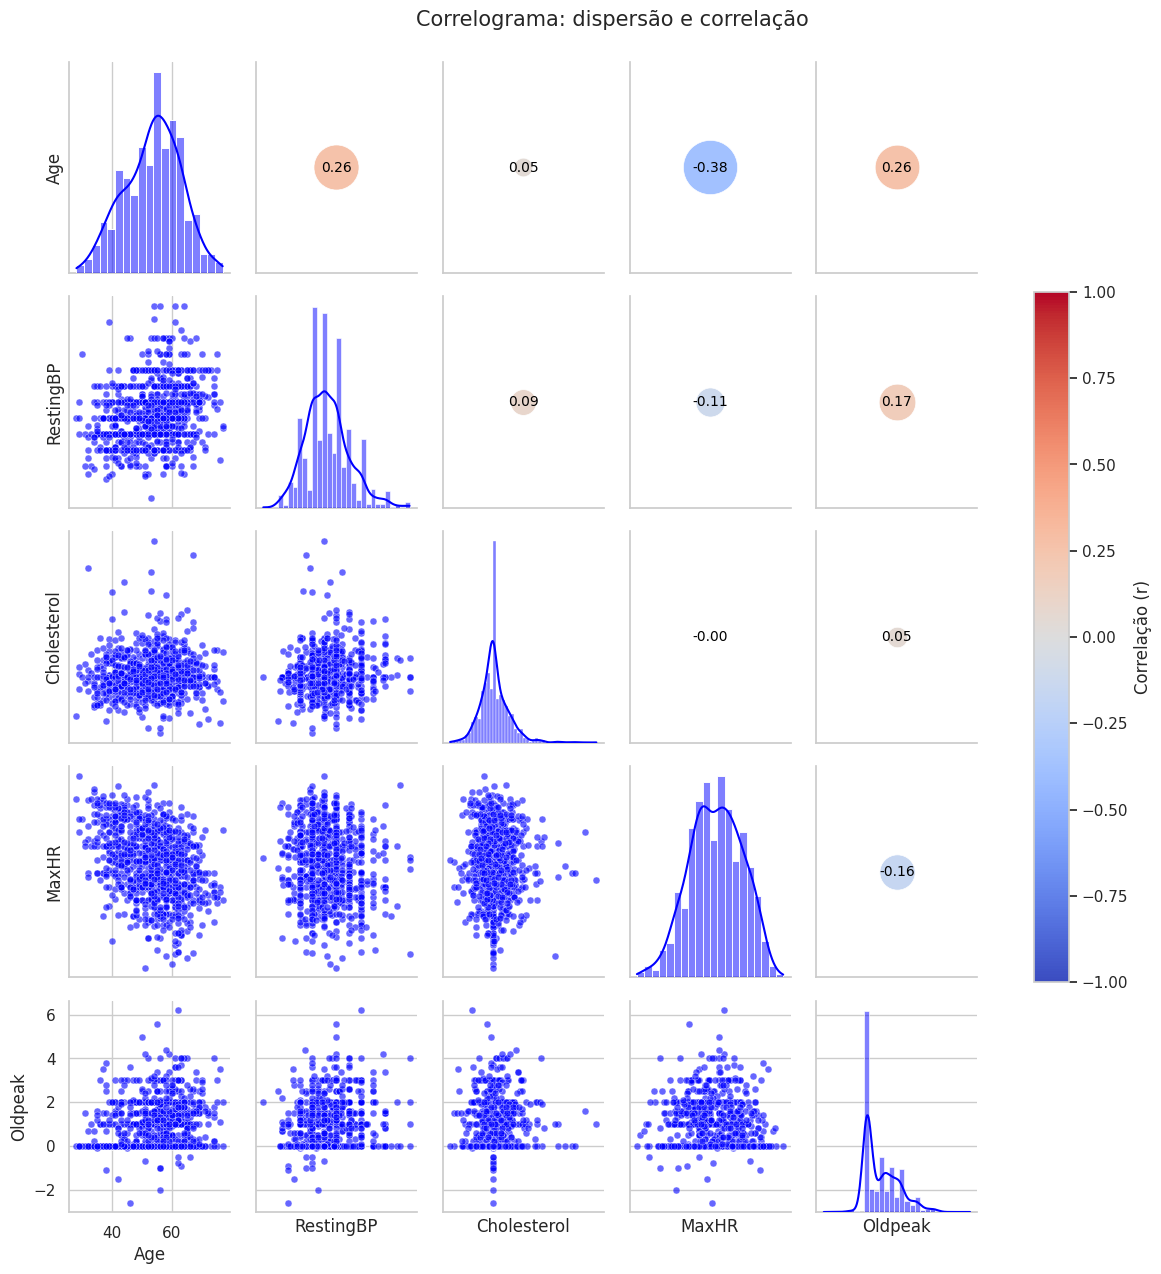

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,
        c=[r], cmap="coolwarm", vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: dispersão e correlação", y=1.02, fontsize=15)
plt.show()

O correlograma junta as três leituras numa figura só: distribuição na diagonal, dispersão embaixo e força da correlação em cima.

Os círculos são todos pequenos, o que confirma o que a matriz já tinha mostrado. O maior é o de `Age` x `MaxHR`, em azul, indicando a relação negativa.

No painel do colesterol dá para ver a marca da imputação: uma faixa horizontal densa de pontos alinhados em 237. É a mesma assinatura que apareceu no jointplot e na comparação antes e depois, agora numa terceira visualização.

## 7. Síntese

### Principais conclusões

**1. Os dados faltantes não vinham como `NaN`, vinham como zero.**
O `isna()` retornava zero em todas as colunas, mas `Cholesterol` e `RestingBP` tinham valores 0, impossíveis em paciente vivo. São 172 ausentes no colesterol (18,74% da base) e 1 na pressão. Identificar isso foi o que sustentou todo o resto: sem a correção, a média do colesterol ficava em 198,8 em vez de 244,6, a skewness aparecia como -0,61 em vez de 1,24, e a regra do IQR acusava 183 outliers em vez de 23.

**2. A ausência do colesterol não é aleatória, e por isso não removi as linhas.**
Entre quem tem a medida, 47,7% têm doença cardíaca. Entre quem não tem, 88,4%. O qui-quadrado deu 91,82 com p ≈ 10⁻²². Remover essas linhas eliminaria quase um quinto do dataset e, principalmente, eliminaria um subgrupo específico de pacientes, trocando um problema de dado faltante por um de viés de seleção. Imputei pela mediana (237,0), por causa da assimetria, e registrei cada imputação na coluna `Cholesterol_imputado`.

**3. O tratamento foi localizado e o efeito dele é rastreável.**
Na comparação antes e depois, `Age`, `RestingBP`, `MaxHR` e `Oldpeak` têm deltas na casa do 0,001. Só `Cholesterol` mudou: desvio padrão de 59,15 para 53,43 e curtose de 4,53 para 6,34. Não é ganho de qualidade, é o efeito de empilhar 171 observações num único valor, e o Shapiro-Wilk confirma isso ao piorar de 0,9357 para 0,9071.

**4. Nenhuma quantitativa é normal, o que definiu o ferramental do resto da análise.**
As cinco rejeitaram o Shapiro-Wilk, então usei Spearman, Mann-Whitney e Kruskal-Wallis, mantendo os paramétricos só como contraste. As variáveis que mais separam os dois grupos são `Oldpeak` (mediana 0,0 contra 1,2), `MaxHR` (150 contra 126) e `Age` (51 contra 57). Entre as qualitativas, `ST_Slope` é a mais informativa: 82,8% dos pacientes com segmento plano têm doença, contra 19,7% dos com segmento em subida.

**5. A base carrega dois vieses sobrepostos.**
São 724 homens contra 193 mulheres, com 63,1% de diagnóstico positivo entre eles e 25,9% entre elas. Além disso, a ausência de exame de colesterol atinge 22,1% dos homens e 5,7% das mulheres. Um modelo treinado aqui herdaria as duas coisas: o viés de quem foi diagnosticado e o de quem teve exame completo. O qui-quadrado confirma que as associações existem, mas não diz se a causa é risco clínico real ou padrão de encaminhamento, e isso não se resolve com estatística.

### Declaração de uso de IA

**Ferramenta:** Claude.

**Para o que usei:**
- Resolver o erro de carregamento do dataset pelo `kagglehub`, que vinha com o parâmetro `file_path` vazio no código gerado pelo Kaggle.
- Adaptar o notebook da aula, feito sobre o Heart Disease da UCI (303 linhas, colunas `chol`, `thal`, `ca`, `cp`), para o dataset que escolhi, que tem 918 linhas e outros nomes de coluna.
- Discutir o mecanismo de dados ausentes e as consequências de cada estratégia de tratamento.
- Revisar os textos discursivos.